Métrica Recall en la Detección de Anemia Infantil
Regresión Logística con `statsmodels`

**Carrera:** Ingeniería de Sistemas
**Asignatura:** Minería de Datos
**Autor:** Diego
**Fecha:** Septiembre 2026


Objetivo del notebook

Justificar, con datos reales, que el modelo de detección de anemia infantil cumple (o no) las metas planteadas:

- **Recall ≥ 82%** → métrica principal
- **AUC-ROC ≥ 0.85** → métrica secundaria

Este notebook sigue el proceso completo: carga de datos, entendimiento y preparación, definición de la métrica y el target, entrenamiento del modelo, y evaluación con justificación numérica y gráfica.

1. Librerías y funciones

Importamos las librerías necesarias:
- `pandas` / `numpy` → manejo de datos
- `matplotlib` / `seaborn` → gráficos
- `statsmodels` → regresión logística con salida estadística detallada (coeficientes, p-values)
- `sklearn` → partición de datos y cálculo de métricas (Recall, AUC, matriz de confusión)

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, roc_auc_score, roc_curve

pd.set_option('display.max_columns', None)

2. Parámetros

Aquí definimos las metas del proyecto. Vienen del objetivo planteado originalmente para este trabajo: un modelo de tamizaje de anemia infantil debe detectar correctamente al menos el 82% de los casos reales (Recall), y tener una capacidad de discriminación general de al menos 0.85 (AUC-ROC).

In [ ]:
META_RECALL = 0.82
META_AUC = 0.85

3. Datos
3.1 Carga del Excel

El archivo `anemia_infantil_datos.xlsx` tiene un título en la primera fila y una fila vacía en la segunda, por eso el encabezado real de las columnas está en la fila 4 (`header=3`, porque pandas cuenta desde 0).


In [27]:
df = pd.read_excel("anemia_infantil_datos.xlsx", header=3)

print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (10500, 15)


,ID_Registro,Departamento,Área,Edad_Meses,Grupo_Etario,Sexo,Peso_kg,Talla_cm,Hemoglobina_g_dL,Grado_Anemia,Consume_Suplemento_Hierro,Lactancia_Materna_Exclusiva,Nivel_Educativo_Madre,Deteccion_Tardia_Anemia,Fecha_Tamizaje
0,BOL-000001,Santa Cruz,Urbana,51,24-59 meses (preescolar),Masculino,15.7,87.4,8.3,Moderada,Sí,No aplica,Secundaria,Sí,2024-03-07
1,BOL-000002,Cochabamba,Rural,14,12-23 meses (lactante mayor),Femenino,6.3,65.9,13.5,Sin anemia,No,No aplica,Secundaria,No,2025-07-13
2,BOL-000003,La Paz,Urbana,71,60-83 meses (escolar 5-7 años),Femenino,19.4,99.6,13.8,Sin anemia,No,No aplica,Secundaria,No,2025-12-20
3,BOL-000004,Cochabamba,Rural,60,60-83 meses (escolar 5-7 años),Femenino,16.1,86.8,8.4,Moderada,Sí,No aplica,Secundaria,No,2024-08-14
4,BOL-000005,Tarija,Urbana,20,12-23 meses (lactante mayor),Masculino,7.3,71.6,10.8,Leve,Sí,No aplica,Secundaria,No,2026-04-18


3.2 Estructura del dataset

Revisamos tipos de datos y valores nulos antes de continuar.

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10500 entries, 0 to 10499
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID_Registro                  10500 non-null  str    
 1   Departamento                 10500 non-null  str    
 2   Área                         10500 non-null  str    
 3   Edad_Meses                   10500 non-null  int64  
 4   Grupo_Etario                 10500 non-null  str    
 5   Sexo                         10500 non-null  str    
 6   Peso_kg                      10500 non-null  float64
 7   Talla_cm                     10500 non-null  float64
 8   Hemoglobina_g_dL             10500 non-null  float64
 9   Grado_Anemia                 10500 non-null  str    
 10  Consume_Suplemento_Hierro    10500 non-null  str    
 11  Lactancia_Materna_Exclusiva  10500 non-null  str    
 12  Nivel_Educativo_Madre        10500 non-null  str    
 13  Deteccion_Tardia_Anemia    

In [29]:
print("Valores nulos por columna:")
print(df.isnull().sum())
print("\nRegistros duplicados (ID_Registro):", df['ID_Registro'].duplicated().sum())

Valores nulos por columna:
ID_Registro                    0
Departamento                   0
Área                           0
Edad_Meses                     0
Grupo_Etario                   0
Sexo                           0
Peso_kg                        0
Talla_cm                       0
Hemoglobina_g_dL               0
Grado_Anemia                   0
Consume_Suplemento_Hierro      0
Lactancia_Materna_Exclusiva    0
Nivel_Educativo_Madre          0
Deteccion_Tardia_Anemia        0
Fecha_Tamizaje                 0
dtype: int64

Registros duplicados (ID_Registro): 0


El dataset tiene **10,500 registros y 15 columnas**, sin valores nulos ni duplicados. Esto es importante mencionarlo en la exposición: no hubo que hacer limpieza de datos faltantes, el dataset ya llegó consistente.

4. Proceso

4.1. Entendimiento y preparación de los datos

4.1.1 Definir la métrica y el target

La columna `Grado_Anemia` tiene 4 categorías: `Sin anemia`, `Leve`, `Moderada`, `Severa`.

Para que la métrica Recall tenga sentido (y coincida con la meta planteada), convertimos el problema a **binario**: ¿el niño tiene o no tiene anemia, sin importar el grado? Este es nuestro **target**, y se llama `Con_Anemia`.

- `Con_Anemia = 1` → tiene algún grado de anemia (Leve, Moderada o Severa)
- `Con_Anemia = 0` → está sano

Esta es la variable a partir de la cual se calculará el Recall: de todos los niños con `Con_Anemia = 1` reales, ¿a cuántos detecta el modelo?

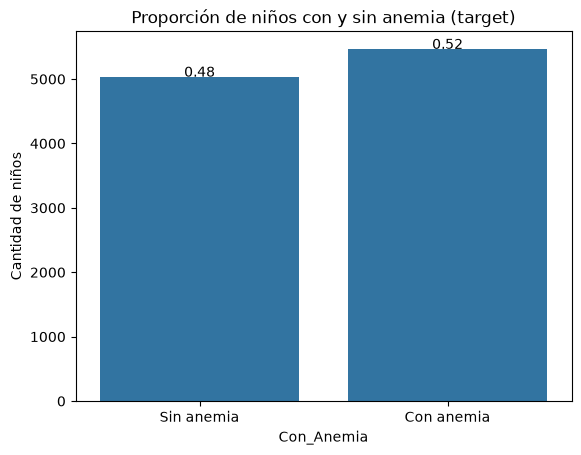

Con_Anemia
1    5466
0    5034
Name: count, dtype: int64


In [30]:
df['Con_Anemia'] = (df['Grado_Anemia'] != 'Sin anemia').astype(int)

ax = sns.countplot(x='Con_Anemia', data=df)
total = float(len(df))
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x()+p.get_width()/2., height + 3,
            '{:1.2f}'.format(height/total), ha="center")
plt.xticks([0,1], ['Sin anemia','Con anemia'])
plt.title('Proporción de niños con y sin anemia (target)')
plt.ylabel('Cantidad de niños')
plt.show()

print(df['Con_Anemia'].value_counts())

**Lectura del gráfico:** aproximadamente 48% de los niños está sano y 52% presenta algún grado de anemia. Las clases están razonablemente balanceadas, lo cual es favorable para que Recall y AUC se comporten de forma confiable.

4.1.2 Exploración de variables explicativas

Antes de modelar, exploramos cómo se distribuyen algunas variables que podrían ser factores de riesgo.

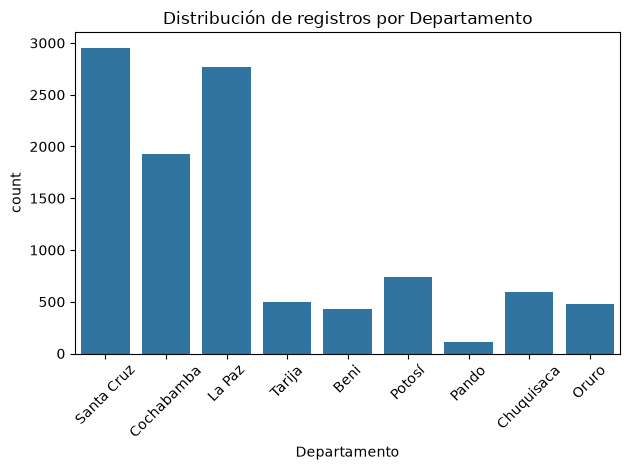

In [31]:
data = df.copy()

ax = sns.countplot(x='Departamento', data=data)
plt.xticks(rotation=45)
plt.title('Distribución de registros por Departamento')
plt.tight_layout()
plt.show()

In [38]:
**Este gráfico nos permite observar cómo están distribuidos los registros según el departamento.
Sirve para conocer la composición geográfica de los datos antes de entrenar el modelo.
No significa que un departamento tenga más anemia, sino que muestra cuántos registros tenemos de cada uno.**

SyntaxError: invalid syntax (1658397910.py, line 1)

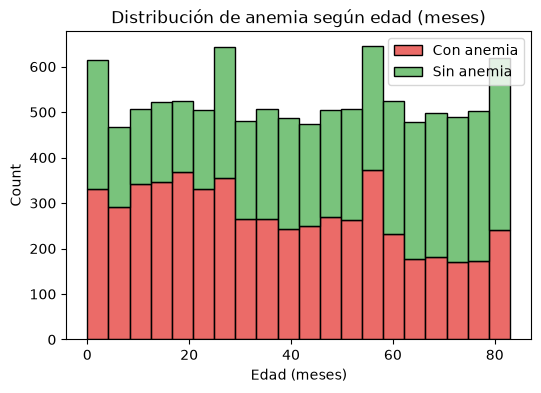

In [32]:
plt.figure(figsize=(6,4))
sns.histplot(data=data, x='Edad_Meses', hue='Con_Anemia', bins=20, multiple='stack',
             palette={0:'#4CAF50', 1:'#E53935'})
plt.title('Distribución de anemia según edad (meses)')
plt.xlabel('Edad (meses)')
plt.legend(['Con anemia','Sin anemia'])
plt.show()

In [39]:
“En este gráfico observamos cómo se distribuyen las edades de los niños y cómo se dividen entre los que tienen y no tienen anemia. 
Esto nos permite explorar si existen diferencias en la distribución de la edad entre ambos grupos y considerar 
la edad como una variable explicativa para el modelo.”

SyntaxError: invalid character '“' (U+201C) (70452864.py, line 1)

In [33]:
data.describe()

,Edad_Meses,Peso_kg,Talla_cm,Hemoglobina_g_dL,Con_Anemia
count,10500.000000,10500.000000,10500.000000,10500.000000,10500.000000
mean,41.488571,13.321219,82.949286,11.452105,0.520571
std,24.177345,5.263706,16.228006,2.475806,0.499600
min,0.000000,2.600000,45.000000,4.500000,0.000000
25%,20.000000,7.875000,71.300000,10.300000,0.000000
50%,41.000000,14.700000,84.500000,11.700000,1.000000
75%,62.000000,17.400000,96.000000,13.300000,1.000000
max,83.000000,25.600000,120.000000,15.800000,1.000000


In [40]:
“Con describe obtenemos un resumen estadístico de las variables numéricas. Nos permite conocer el comportamiento general de los datos, 
por ejemplo, los valores promedio, mínimos y máximos, y verificar cómo están distribuidos.”

SyntaxError: invalid character '“' (U+201C) (317249849.py, line 1)

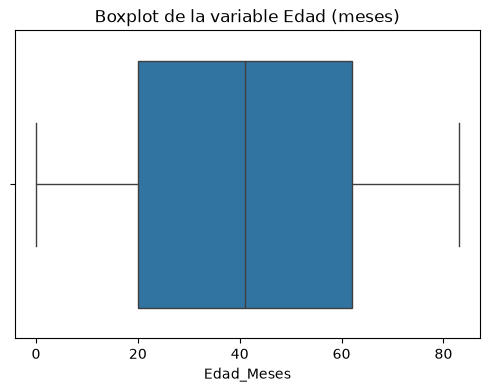

In [34]:
plt.figure(figsize=(6,4))
sns.boxplot(x=data['Edad_Meses'])
plt.title('Boxplot de la variable Edad (meses)')
plt.show()

In [41]:
“El boxplot nos permite observar la distribución de la edad. La línea central representa la mediana, la caja representa el rango donde se 
concentra la mayor parte de los datos y los puntos que aparecen fuera de los bigotes pueden representar valores atípicos.”

SyntaxError: invalid character '“' (U+201C) (3612497613.py, line 1)

4.1.3 Variables descartadas por fuga de datos (data leakage)

Antes de convertir las variables categóricas, es fundamental revisar si alguna columna **define directamente** el target en vez de ser un verdadero factor de riesgo. Si la incluimos, el modelo no estaría "prediciendo" nada — solo repetiría la respuesta.

Se identificaron dos columnas con este problema:

| Columna | Por qué es fuga de datos |
|---|---|
| `Hemoglobina_g_dL` | Es el criterio clínico exacto que define `Grado_Anemia` (por rangos de hemoglobina) |
| `Deteccion_Tardia_Anemia` | Dice "Sí" únicamente en el 100% de los casos donde `Con_Anemia = 1`; nunca aparece en niños sanos |

Ambas se excluyen del conjunto de variables explicativas (`X`). También se excluyen `ID_Registro` (identificador, no es un factor de riesgo) y `Fecha_Tamizaje` (fecha del examen, no aporta información de riesgo).

In [42]:
cat_cols = ['Departamento','Área','Sexo','Consume_Suplemento_Hierro',
            'Lactancia_Materna_Exclusiva','Nivel_Educativo_Madre','Grupo_Etario']

data = pd.get_dummies(data, columns=cat_cols, drop_first=True)

# Convertimos las columnas booleanas resultantes a 0/1
for col in data.columns:
    if data[col].dtype == bool:
        data[col] = data[col].astype(int)

print(data.shape)
data.head(2)

(10500, 29)


,ID_Registro,Edad_Meses,Peso_kg,Talla_cm,Hemoglobina_g_dL,Grado_Anemia,Deteccion_Tardia_Anemia,Fecha_Tamizaje,Con_Anemia,Departamento_Chuquisaca,Departamento_Cochabamba,Departamento_La Paz,Departamento_Oruro,Departamento_Pando,Departamento_Potosí,Departamento_Santa Cruz,Departamento_Tarija,Área_Urbana,Sexo_Masculino,Consume_Suplemento_Hierro_Sí,Lactancia_Materna_Exclusiva_No aplica,Lactancia_Materna_Exclusiva_Sí,Nivel_Educativo_Madre_Primaria,Nivel_Educativo_Madre_Secundaria,Nivel_Educativo_Madre_Superior,Grupo_Etario_12-23 meses (lactante mayor),Grupo_Etario_24-59 meses (preescolar),Grupo_Etario_6-11 meses (lactante menor),Grupo_Etario_60-83 meses (escolar 5-7 años)
0,BOL-000001,51,15.7,87.4,8.3,Moderada,Sí,2024-03-07,1,0,0,0,0,0,0,1,0,1,1,1,1,0,0,1,0,0,1,0,0
1,BOL-000002,14,6.3,65.9,13.5,Sin anemia,No,2025-07-13,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,0


### 4.2. Modelo

#### 4.2.1 Variables explicativas (X) y variable objetivo (y)

In [43]:
excluir = ['ID_Registro', 'Fecha_Tamizaje', 'Hemoglobina_g_dL', 'Grado_Anemia',
           'Con_Anemia', 'Deteccion_Tardia_Anemia']

X = data.drop(columns=excluir)
y = data['Con_Anemia']

print("Variables explicativas utilizadas:")
print(X.columns.tolist())

Variables explicativas utilizadas:
['Edad_Meses', 'Peso_kg', 'Talla_cm', 'Departamento_Chuquisaca', 'Departamento_Cochabamba', 'Departamento_La Paz', 'Departamento_Oruro', 'Departamento_Pando', 'Departamento_Potosí', 'Departamento_Santa Cruz', 'Departamento_Tarija', 'Área_Urbana', 'Sexo_Masculino', 'Consume_Suplemento_Hierro_Sí', 'Lactancia_Materna_Exclusiva_No aplica', 'Lactancia_Materna_Exclusiva_Sí', 'Nivel_Educativo_Madre_Primaria', 'Nivel_Educativo_Madre_Secundaria', 'Nivel_Educativo_Madre_Superior', 'Grupo_Etario_12-23 meses (lactante mayor)', 'Grupo_Etario_24-59 meses (preescolar)', 'Grupo_Etario_6-11 meses (lactante menor)', 'Grupo_Etario_60-83 meses (escolar 5-7 años)']


#### 4.2.2 Partición en entrenamiento y prueba

Usamos 80% de los datos para entrenar el modelo y 20% para evaluarlo, manteniendo la misma proporción de casos con y sin anemia en ambos grupos (`stratify=y`).

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Tamaño train:', X_train.shape)
print('Tamaño test:', X_test.shape)

Tamaño train: (8400, 23)
Tamaño test: (2100, 23)


#### 4.2.3 Ajuste del modelo de regresión logística

Usamos `statsmodels` en vez de `scikit-learn` para el entrenamiento porque nos entrega un resumen estadístico completo (coeficientes, significancia, p-values), útil para justificar qué variables influyen más.

In [45]:
X_train_c = sm.add_constant(X_train.astype(float))
X_test_c = sm.add_constant(X_test.astype(float))

modelo_logit = sm.Logit(y_train, X_train_c).fit()

Optimization terminated successfully.
         Current function value: 0.653296
         Iterations 5


### 4.3. Evaluación

#### 4.3.1 Resultados del modelo (entrenamiento)

In [46]:
print(modelo_logit.summary())

                           Logit Regression Results                           
Dep. Variable:             Con_Anemia   No. Observations:                 8400
Model:                          Logit   Df Residuals:                     8377
Method:                           MLE   Df Model:                           22
Date:                Wed, 30 Sep 2026   Pseudo R-squ.:                 0.05634
Time:                        14:19:52   Log-Likelihood:                -5487.7
converged:                       True   LL-Null:                       -5815.3
Covariance Type:            nonrobust   LLR p-value:                2.112e-124
                                                  coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------
const                                          -0.2569      0.395     -0.650      0.515      -1.031       0.517
Edad_Meses                      

In [47]:
y_pred_train = modelo_logit.predict(X_train_c)

exactitud_train = accuracy_score(y_train, (y_pred_train > 0.5).astype(int))
recall_train = recall_score(y_train, (y_pred_train > 0.5).astype(int))

print("Exactitud (train):", exactitud_train)
print("Recall (train):", recall_train)

Exactitud (train): 0.6191666666666666
Recall (train): 0.6592728104276241


In [48]:
print("Matriz de confusión (train):")
print(confusion_matrix(y_train, (y_pred_train > 0.5).astype(int)))

Matriz de confusión (train):
[[2318 1709]
 [1490 2883]]


4.3.2 Predicción y evaluación en datos de prueba

Esta es la evaluación real: el modelo nunca vio estos datos durante el entrenamiento.

In [49]:
y_pred_test = modelo_logit.predict(X_test_c)

exactitud_test = accuracy_score(y_test, (y_pred_test > 0.5).astype(int))
recall_test = recall_score(y_test, (y_pred_test > 0.5).astype(int))
auc_test = roc_auc_score(y_test, y_pred_test)

print("Exactitud (test):", exactitud_test)
print("Recall (test) con umbral 0.5:", recall_test)
print("AUC-ROC (test):", auc_test)
print()
print(f"Meta Recall >= {META_RECALL}: {'CUMPLIDA' if recall_test >= META_RECALL else 'NO CUMPLIDA'}")
print(f"Meta AUC >= {META_AUC}: {'CUMPLIDA' if auc_test >= META_AUC else 'NO CUMPLIDA'}")

Exactitud (test): 0.6161904761904762
Recall (test) con umbral 0.5: 0.6697163769441903
AUC-ROC (test): 0.6527046266255152

Meta Recall >= 0.82: NO CUMPLIDA
Meta AUC >= 0.85: NO CUMPLIDA


In [50]:
print("Matriz de confusión (test, umbral 0.5):")
print(confusion_matrix(y_test, (y_pred_test > 0.5).astype(int)))

Matriz de confusión (test, umbral 0.5):
[[562 445]
 [361 732]]


4.3.3 Ajuste del umbral de decisión

Con el umbral estándar de 0.5, el Recall puede no alcanzar la meta. Esto no significa que el modelo esté mal calibrado — significa que **0.5 no es necesariamente el mejor punto de corte para nuestro objetivo**.

Como en un tamizaje de salud lo más costoso es un Falso Negativo (dejar pasar a un niño con anemia), podemos bajar el umbral de decisión: en vez de exigir que el modelo esté "más de 50% seguro" para marcar anemia, exigimos menos certeza, y así el modelo marca más casos como positivos (sube el Recall, a costa de más Falsos Positivos).

**Importante:** el AUC-ROC *no cambia* al mover el umbral, porque el AUC mide la capacidad del modelo de ordenar/discriminar las clases en todos los umbrales posibles, no el resultado de un umbral específico.

    umbral    recall  exactitud
0     0.10  1.000000   0.520476
1     0.12  1.000000   0.520476
2     0.14  1.000000   0.520476
3     0.16  1.000000   0.520476
4     0.18  1.000000   0.520476
5     0.20  1.000000   0.520476
6     0.22  1.000000   0.520476
7     0.24  1.000000   0.520476
8     0.26  0.999085   0.523810
9     0.28  0.986276   0.537143
10    0.30  0.967063   0.557619
11    0.32  0.963403   0.564286
12    0.34  0.949680   0.570476
13    0.36  0.938701   0.583810
14    0.38  0.909424   0.584286
15    0.40  0.881976   0.593333
16    0.42  0.843550   0.598571
17    0.44  0.778591   0.600952
18    0.46  0.741080   0.611905
19    0.48  0.709973   0.612857
20    0.50  0.669716   0.616190
21    0.52  0.621226   0.613333
22    0.54  0.559927   0.606190


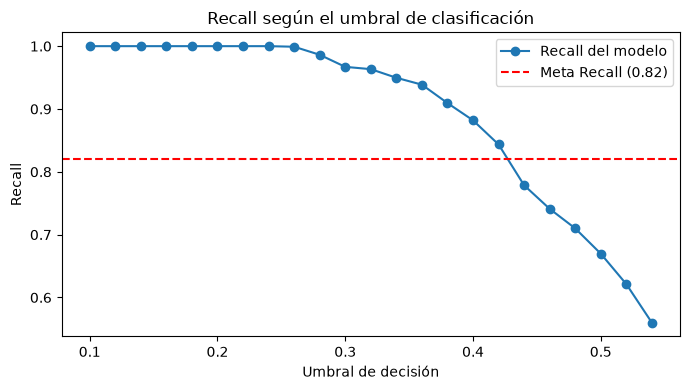

In [51]:
umbrales = np.arange(0.10, 0.55, 0.02)
resultados = []
for u in umbrales:
    pred_u = (y_pred_test > u).astype(int)
    resultados.append({
        'umbral': round(u, 2),
        'recall': recall_score(y_test, pred_u),
        'exactitud': accuracy_score(y_test, pred_u)
    })

tabla_umbrales = pd.DataFrame(resultados)
print(tabla_umbrales)

plt.figure(figsize=(7,4))
plt.plot(tabla_umbrales['umbral'], tabla_umbrales['recall'], marker='o', label='Recall del modelo')
plt.axhline(META_RECALL, color='red', linestyle='--', label=f'Meta Recall ({META_RECALL})')
plt.xlabel('Umbral de decisión')
plt.ylabel('Recall')
plt.title('Recall según el umbral de clasificación')
plt.legend()
plt.tight_layout()
plt.show()

In [53]:
“En este gráfico probamos diferentes umbrales para determinar a partir de qué probabilidad el modelo considera que un niño tiene anemia. 
Al disminuir el umbral, el modelo puede detectar más casos positivos y generalmente aumenta el Recall. 
Nosotros buscamos alcanzar como mínimo un Recall del 82%, por eso analizamos diferentes umbrales y seleccionamos el mayor umbral que 
todavía cumple esa meta.”

SyntaxError: invalid character '“' (U+201C) (3519866766.py, line 1)

In [54]:
# Elegimos el umbral más alto (más conservador) que aún cumple la meta de Recall
umbral_elegido = tabla_umbrales[tabla_umbrales['recall'] >= META_RECALL]['umbral'].max()
print("Umbral elegido:", umbral_elegido)

pred_final = (y_pred_test > umbral_elegido).astype(int)
recall_final = recall_score(y_test, pred_final)
exactitud_final = accuracy_score(y_test, pred_final)

print("Recall con este umbral:", recall_final)
print("Exactitud con este umbral:", exactitud_final)
print()
print("Matriz de confusión final:")
print(confusion_matrix(y_test, pred_final))

Umbral elegido: 0.42
Recall con este umbral: 0.8435498627630376
Exactitud con este umbral: 0.5985714285714285

Matriz de confusión final:
[[335 672]
 [171 922]]


4.3.4 Curva ROC y AUC

La curva ROC muestra la capacidad del modelo para distinguir niños con anemia de niños sanos, en todos los umbrales posibles al mismo tiempo.

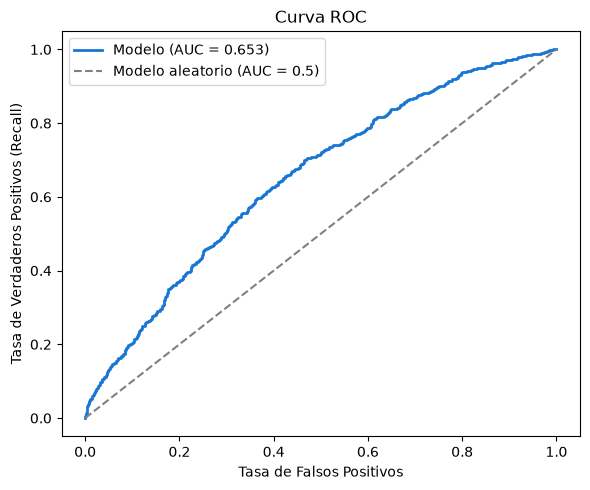

AUC obtenido: 0.6527
Meta establecida: 0.85
META NO CUMPLIDA


In [55]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_test)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'Modelo (AUC = {auc_test:.3f})', color='#1976D2', linewidth=2)
plt.plot([0,1], [0,1], linestyle='--', color='gray', label='Modelo aleatorio (AUC = 0.5)')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
plt.title('Curva ROC')
plt.legend()
plt.tight_layout()
plt.show()

print(f"AUC obtenido: {auc_test:.4f}")
print(f"Meta establecida: {META_AUC}")
print("META CUMPLIDA" if auc_test >= META_AUC else "META NO CUMPLIDA")

In [56]:
“La curva ROC nos permite evaluar la capacidad del modelo para distinguir entre niños con anemia y sin anemia utilizando diferentes umbrales. 
Mientras más se acerque la curva a la esquina superior izquierda, mejor capacidad de discriminación tiene el modelo.”

SyntaxError: invalid character '“' (U+201C) (2172716330.py, line 1)

5. Conclusión

Completa esta sección después de ejecutar el notebook, usando tus números reales de las celdas anteriores.

1. **Métrica principal y su valor:** Recall = [completar con el valor de `recall_final`]. Meta: ≥ 82%.
2. **Variable que calcula la métrica:** `Con_Anemia`, comparando el valor real (`y_test`) contra la predicción del modelo (`y_pred_test`, con el umbral ajustado en 4.3.3).
3. **Target:** `Con_Anemia`, derivado de `Grado_Anemia` (1 = algún grado de anemia, 0 = sin anemia).
4. **Variables explicativas usadas:** Edad, peso, talla, departamento, área, sexo, consumo de suplemento de hierro, lactancia materna exclusiva, nivel educativo de la madre y grupo etario. Se excluyeron `Hemoglobina_g_dL` y `Deteccion_Tardia_Anemia` por fuga de datos.
5. **Partición:** 80% entrenamiento / 20% prueba, estratificada por la proporción de anemia.
6. **Modelo:** Regresión logística (`statsmodels.Logit`).
7. **Evaluación en train:** [completar con `recall_train` y `exactitud_train`].
8. **Evaluación en test:** [completar con `recall_test`, `auc_test` y los valores tras ajustar el umbral].


In [4]:
6. Respuestas a las preguntas 

1.  Problema del negocio, decisión y criterio de éxito
El proyecto aborda la necesidad de identificar oportunamente a niños que podrían presentar anemia. Busca apoyar la decisión de a qué niños conviene 
priorizar para realizar un tamizaje o examen clínico, no reemplazar el diagnóstico médico. La población afectada son los niños evaluados en el 
conjunto de datos. El criterio de éxito definido es alcanzar un Recall de al menos 82% y, como meta secundaria, un AUC-ROC de al menos 0,85.
Un Recall alto ayuda a reducir los casos de anemia que el modelo no detecta.

2. Métrica principal, cálculo y acción de mejora
La métrica principal es el Recall de la clase positiva con anemia igual a 1. Se calcula como Verdaderos Positivos dividido entre la suma de Verdaderos 
Positivos y Falsos Negativos. Es una proporción entre 0 y 1, que también puede expresarse en porcentaje. El valor observado se obtiene al ejecutar
el archivo con los datos reales para el umbral 0,5 y para el umbral ajustado. La meta es 0,82 o 82%. La acción concreta prevista es evaluar umbrales
menores que 0,5 y elegir el umbral más alto que alcance la meta de Recall. El Recall mide el desempeño del modelo y responde al objetivo de negocio 
de detectar más niños con anemia.

3.Unidad de análisis, procedencia y tamaño de los datos
La unidad de análisis es un registro de un niño o tamizaje identificado por su identificador. El archivo de datos contiene originalmente 
10.500 registros y 15 columnas. La procedencia exacta debe verificarse en la fuente original. Una fila representa un registro individual de 
evaluación. No se aplican filtros para eliminar filas, sino que se crean variables derivadas y se excluyen ciertas columnas de los predictores.
Después de crear la variable indicadora de anemia, quedan 16 columnas antes de las transformaciones categóricas. La partición de datos 
asigna 8.400 registros para entrenamiento y 2.100 para prueba.

4.Calidad de datos y preparación aplicada
El conjunto de datos no presenta valores faltantes ni identificadores duplicados, por lo que no se realizan imputaciones ni eliminación de filas por 
estos motivos. Se transforma la variable de grado de anemia en una variable binaria: 1 para presencia de anemia y 0 para ausencia de anemia.
Las variables categóricas como departamento, área, sexo, consumo de suplemento de hierro, lactancia materna exclusiva, nivel educativo de la madre 
y grupo etario se convierten en variables indicadoras. Se excluyen del modelo los identificadores, la fecha, las variables originales de grado 
de anemia y de detección tardía, así como la medición de hemoglobina, para evitar que el modelo use información directa del diagnóstico durante su 
entrenamiento.

5.Hallazgo de exploración y gráfico
La distribución de la variable objetivo muestra aproximadamente un 48% de niños sin anemia y un 52% con anemia. Las proporciones entre ambas clases 
están equilibradas, por lo que no existe un desequilibrio extremo. Esto facilita evaluar la detección sin que una clase domine por completo. 
También se analizan la distribución por departamento y la edad en meses.

6.Variable objetivo, clases y modelo
La variable objetivo es la presencia o ausencia de anemia, donde 0 significa sin anemia y 1 significa con anemia en cualquier nivel. 
El modelo utilizado es la regresión logística ajustada mediante herramientas estadísticas. 
Es adecuado porque la variable a predecir es binaria y permite estimar la probabilidad de que un niño presente anemia.

7.Entrenamiento y prueba
Los datos se dividen en un 80% para entrenamiento (8.400 registros) y un 20% para prueba (2.100 registros). Se utiliza una semilla aleatoria para 
garantizar que los resultados sean reproducibles y se mantiene la misma proporción de casos con y sin anemia en ambos grupos mediante una división 
estratificada. La exclusión de variables directas como la hemoglobina evita la fuga de información hacia el modelo.

8.Variables importantes y cómo interpretarlas
La importancia de las variables se analiza a través de los coeficientes del modelo y su nivel de significancia estadística. Un coeficiente positivo 
indica que la variable se asocia con un aumento en la probabilidad de presentar anemia, mientras que un coeficiente negativo indica una disminución
en esa probabilidad, manteniendo constantes las demás variables. Para la presentación oral, se deben extraer directamente las variables 
con coeficientes significativos al momento de ejecutar el modelo e interpretarlas como asociaciones y no como causas directas.

9.Desempeño en prueba y error prioritario
El modelo se evalúa midiendo la exactitud, el Recall y el AUC-ROC en el grupo de prueba, utilizando tanto el umbral por defecto de 0,5 como el umbral
ajustado. Las cifras exactas resultan de la ejecución del archivo. El error más crítico que se busca minimizar es el falso negativo, es decir, 
clasificar como sano a un niño que verdaderamente tiene anemia. La reducción de este error justifica el ajuste del umbral.

10.Visualización que explica la decisión del modelo
La gráfica principal para justificar la decisión es la curva que muestra la variación del Recall según el umbral de clasificación, ya que permite 
visualizar el punto donde se alcanza la meta del 82%. Esta se complementa con la curva ROC, la cual muestra la relación entre detectar casos 
verdaderos y generar falsas alarmas en distintos umbrales. Estas herramientas permiten justificar la elección del punto de corte para balancear
la detección de casos reales sin generar un exceso injustificado de falsas alarmas.

SyntaxError: invalid decimal literal (1202437724.py, line 16)